# BasketWise: Grocery Basket Recommender

**CSE 426 — Data Mining and Warehouse Lab | Solo project**

Every grocery receipt hides patterns: people who buy pasta often buy tomato sauce, and people
who buy coffee often buy sugar. This notebook takes ~38,000 raw grocery purchase records,
cleans them, turns them into shopping baskets, mines **association rules** with **Apriori** and
**FP-Growth**, and builds a small **recommender system** ("customers who buy X also buy Y").

The cleaned results are exported as four JSON files that a companion Next.js website displays.
**No mining happens in the website** — the notebook is the source of truth.

**Dataset:** `data/Groceries_dataset.csv` (Kaggle *Groceries Dataset*), with three columns:
`Member_number`, `Date`, and `itemDescription`. One row is one item bought by one member on one
date. If the real file is missing, the notebook automatically creates a clearly-labelled
synthetic stand-in.

**Lab topics used:** data preprocessing, association rule mining (support, confidence, lift),
Apriori vs FP-Growth, and recommendation systems.

In [1]:
!pip install -q mlxtend


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# All imports live here, so no later cell can fail with NameError.
import json
import sys
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="Greens_r")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
print("Libraries loaded.")

Libraries loaded.


## Part 1: Load and explore the data

Before cleaning anything, we look at the raw file exactly as it is. This tells us the size of
the dataset, which columns exist, what the values look like, and how much cleaning will be
needed.

In [3]:
# Resolve the dataset path once. In Colab we try Google Drive first, then the repo folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts").exists() and (PROJECT_ROOT.parent / "scripts").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent  # handles nbconvert running from notebooks/

IN_COLAB = "google.colab" in sys.modules
COLAB_PATH = Path("/content/drive/MyDrive/Data Mining/Groceries_dataset.csv")
LOCAL_PATH = PROJECT_ROOT / "data" / "Groceries_dataset.csv"

if IN_COLAB and COLAB_PATH.exists():
    DATA_PATH = COLAB_PATH
else:
    DATA_PATH = LOCAL_PATH

# If neither file exists, generate the documented synthetic fallback.
if not DATA_PATH.exists():
    import subprocess
    print("Dataset not found - generating the synthetic fallback ...")
    subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / "make_synthetic_data.py")],
        check=True, cwd=str(PROJECT_ROOT),
    )
    DATA_PATH = LOCAL_PATH

DATA_SOURCE = "synthetic" if (PROJECT_ROOT / "data" / "DATA_SOURCE.txt").exists() else "real"
print("Data file  :", DATA_PATH.resolve())
print("Data source:", DATA_SOURCE)
if DATA_SOURCE == "synthetic":
    print("=" * 76)
    print("WARNING: SYNTHETIC DEMO DATA IS IN USE.")
    print("For the real analysis, replace data/Groceries_dataset.csv with the Kaggle")
    print("file and delete data/DATA_SOURCE.txt, then re-run this notebook.")
    print("=" * 76)

Data file  : D:\Projects\data mmining project\data\Groceries_dataset.csv
Data source: synthetic
For the real analysis, replace data/Groceries_dataset.csv with the Kaggle
file and delete data/DATA_SOURCE.txt, then re-run this notebook.


In [4]:
# A first plain read: no cleaning, no special options.
df_raw = pd.read_csv(DATA_PATH)

# Remember the raw numbers so we can show a before/after comparison later.
before_rows = len(df_raw)
before_items = df_raw["itemDescription"].nunique()
before_members = df_raw["Member_number"].nunique()

print(f"Rows: {len(df_raw):,}")
print(f"Columns: {list(df_raw.columns)}")
df_raw.head(10)

Rows: 38,120
Columns: ['Member_number', 'Date', 'itemDescription']


,Member_number,Date,itemDescription
0,2573,12-03-2015,rolls/buns
1,1892,28-12-2015,whipped/sour cream
2,1009,07-01-2015,sausage rolls
3,2980,13-09-2015,salt
4,1483,06-10-2015,soups
5,2890,26-01-2015,napkins
6,1206,25-11-2014,sausage
7,1119,31-05-2015,shopping bags
8,2704,23-05-2014,soda
9,3417,24-10-2015,yogurt


In [5]:
# Structure, numeric summary and cardinality.
df_raw.info()
print("\n--- describe() ---")
display(df_raw.describe())
print("\n--- unique values per column ---")
print(df_raw.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38120 entries, 0 to 38119
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38120 non-null  int64 
 1   Date             38120 non-null  object
 2   itemDescription  38120 non-null  object
dtypes: int64(1), object(2)
memory usage: 893.6+ KB

--- describe() ---


,Member_number
count,38120.000000
mean,2291.365241
std,750.725990
min,1000.000000
25%,1643.000000
50%,2274.000000
75%,2939.000000
max,3599.000000



--- unique values per column ---
Member_number      2482
Date                730
itemDescription     389
dtype: int64


**What to notice:** the file has three columns and around 38,000 rows. `Member_number` is an ID,
not a quantity, so its `describe()` values are not meaningful. `Date` is still text at this
stage. The item names are inconsistent: the same product appears with different capitalisation
and extra spaces, which is why preprocessing matters.

In [6]:
# The 15 most frequent RAW item strings (before any cleaning).
top15_raw = df_raw["itemDescription"].value_counts().head(15)
display(top15_raw.to_frame("purchase_lines"))

,purchase_lines
itemDescription,
whole milk,4298
other vegetables,2693
yogurt,2612
rolls/buns,1858
whipped/sour cream,1543
tropical fruit,1479
root vegetables,1467
soda,1435
brown bread,1299


The list is dominated by everyday staples (whole milk, vegetables, rolls/buns). Because the
names are not normalised yet, one product can appear more than once under different spellings.
Part 2 fixes that.

## Part 2: Data preprocessing

Raw retail data is messy. Here we:

1. look for ordinary missing values,
2. treat hidden missing values such as `?` as missing,
3. remove exact duplicate rows,
4. standardise item names,
5. parse the date column and add `Year` / `Month`.

Every decision is explained so the pipeline is easy to defend in a lab report.

In [7]:
# Ordinary missing values (standard NaN) in the raw read.
missing = df_raw.isna().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
display(missing_table)

if missing.sum() > 0:
    missing[missing > 0].plot(kind="bar", color="#2f855a")
    plt.title("Missing values per column (plain read)")
    plt.ylabel("Number of rows")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No standard NaN values in the plain read - but hidden missing values may still exist.")

,missing,percent
Member_number,0,0.0
Date,0,0.0
itemDescription,0,0.0


No standard NaN values in the plain read - but hidden missing values may still exist.


In [8]:
# Hidden missing values: re-read the file with extra tokens recognised as NaN.
HIDDEN_MISSING = ["?", "missing", "n/a", "--", "", "NULL"]
df = pd.read_csv(DATA_PATH, na_values=HIDDEN_MISSING)

before_hidden = int(df_raw.isna().sum().sum())
after_hidden = int(df.isna().sum().sum())
print(f"Missing cells before hidden-value handling: {before_hidden}")
print(f"Missing cells after  hidden-value handling: {after_hidden}")
print(f"Rows containing a literal '?' item: {(df_raw['itemDescription'] == '?').sum():,}")
display(df.isna().sum().to_frame("missing_after_reRead"))

Missing cells before hidden-value handling: 0
Missing cells after  hidden-value handling: 152
Rows containing a literal '?' item: 152


,missing_after_reRead
Member_number,0
Date,0
itemDescription,152


**What to notice:** the second read finds more missing cells. Values that looked like text
(`?`, `n/a`, empty strings) are now correctly treated as unknown. Those rows cannot be used for
mining, so we remove them rather than inventing item names.

In [9]:
# Drop rows that cannot contribute a usable transaction.
rows_before_drop = len(df)
df = df.dropna(subset=["Member_number", "Date", "itemDescription"]).copy()
print(f"Dropped {rows_before_drop - len(df):,} incomplete rows; {len(df):,} remain.")

Dropped 152 incomplete rows; 37,968 remain.


In [10]:
# Exact duplicate rows: count them, then keep one copy of each.
exact_dupes = int(df.duplicated().sum())
print(f"Exact duplicate rows found: {exact_dupes:,}")

rows_before_dupes = len(df)
df = df.drop_duplicates().copy()
print(f"Rows before: {rows_before_dupes:,} | after removing exact duplicates: {len(df):,}")

Exact duplicate rows found: 131


Rows before: 37,968 | after removing exact duplicates: 37,837


**Why only exact duplicates?** In basket data, the same member can legitimately buy the same
item on two different dates, so we must not remove those rows. A true duplicate receipt line is
an exact copy of all three columns, and that is what we remove. Later, when we build a basket,
we also collapse repeated items inside the *same* basket into one set.

In [11]:
# Standardise item names: trim, lowercase, collapse internal whitespace.
df["itemDescription"] = (
    df["itemDescription"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Small spelling map for variants that survive the basic cleaning.
SPELLING_FIXES = {"uht milk": "uht-milk"}
df["itemDescription"] = df["itemDescription"].replace(SPELLING_FIXES)

print("Unique item names after cleaning:", df["itemDescription"].nunique())
display(df["itemDescription"].value_counts().head(10).to_frame("purchase_lines"))

Unique item names after cleaning:

 158


,purchase_lines
itemDescription,
whole milk,4355
other vegetables,2732
yogurt,2640
rolls/buns,1891
whipped/sour cream,1572
tropical fruit,1517
root vegetables,1493
soda,1458
brown bread,1320


In [12]:
# Parse the date as DAY-FIRST (21-07-2015 = 21 July 2015) and add time helpers.
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
bad_dates = int(df["Date"].isna().sum())
df = df.dropna(subset=["Date"]).copy()

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M").astype(str)

print(f"Unparseable dates removed: {bad_dates}")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
df[["Member_number", "Date", "Year", "Month", "itemDescription"]].head()

Unparseable dates removed: 0


Date range: 2014-01-01 to 2015-12-31


,Member_number,Date,Year,Month,itemDescription
0,2573,2015-03-12,2015,2015-03,rolls/buns
1,1892,2015-12-28,2015,2015-12,whipped/sour cream
2,1009,2015-01-07,2015,2015-01,sausage rolls
3,2980,2015-09-13,2015,2015-09,salt
4,1483,2015-10-06,2015,2015-10,soups


In [13]:
# Before/after summary of the cleaning work.
before_stats = {
    "rows": before_rows,
    "unique items": before_items,
    "unique members": before_members,
}
after_stats = {
    "rows": len(df),
    "unique items": df["itemDescription"].nunique(),
    "unique members": df["Member_number"].nunique(),
}
cleaning_summary = pd.DataFrame({"before": before_stats, "after": after_stats})
cleaning_summary["change"] = cleaning_summary["after"] - cleaning_summary["before"]
display(cleaning_summary)

,before,after,change
rows,38120,37837,-283
unique items,389,158,-231
unique members,2482,2482,0


### Cleaning steps applied

- Read `?`, `missing`, `n/a`, `--`, empty strings and `NULL` as missing values.
- Removed rows with a missing member, date or item.
- Removed exact duplicate rows only; kept legitimate repeat purchases on different dates.
- Trimmed whitespace, lowercased item names, collapsed repeated spaces and fixed one spelling variant.
- Parsed `Date` as **day-first** and added `Year` and `Month`.
- Collapsed repeated items *inside a basket* later, when baskets are built.

The unique item count falls sharply because mixed-case and spaced variants are merged into one
canonical name. Fewer item names means more reliable support counts.

## Part 3: Exploratory plots

Three quick charts give a feel for demand, seasonality and basket size before mining.

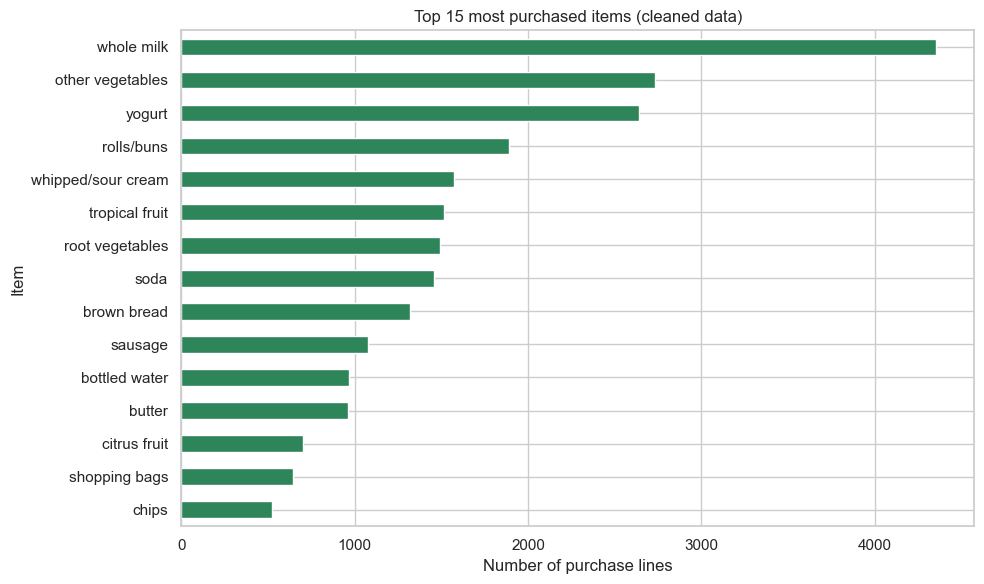

In [14]:
# Chart 1: the 15 most purchased items after cleaning.
top15 = df["itemDescription"].value_counts().head(15).sort_values()

plt.figure(figsize=(10, 6))
top15.plot(kind="barh", color="#2f855a")
plt.title("Top 15 most purchased items (cleaned data)")
plt.xlabel("Number of purchase lines")
plt.ylabel("Item")
plt.tight_layout()
plt.show()

**Insight:** a small group of staples accounts for a large share of all purchase lines. These
popular items will also have the highest support, so they are the easiest to recommend.

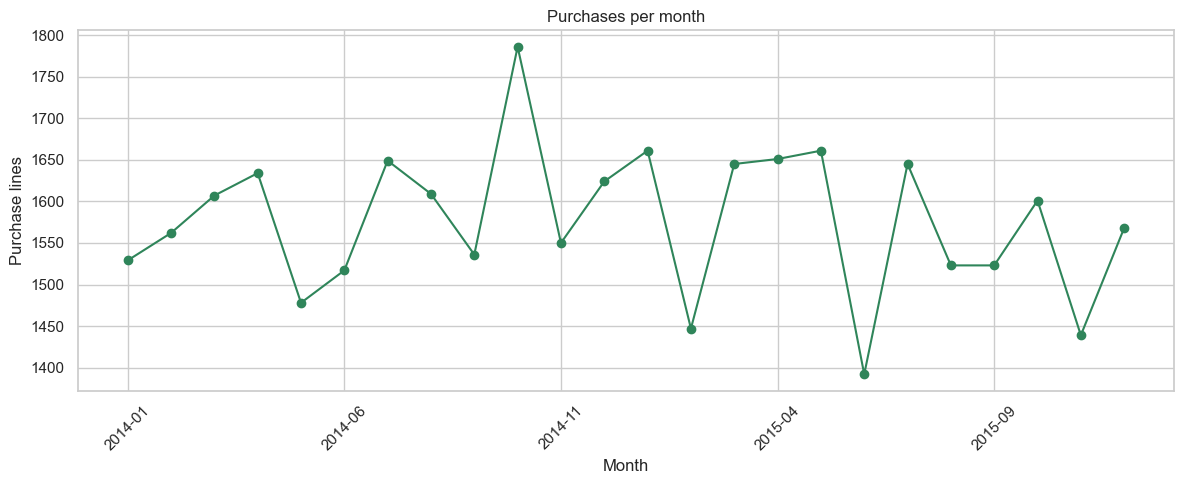

In [15]:
# Chart 2: purchase lines per month.
monthly = df.groupby("Month").size()

plt.figure(figsize=(12, 5))
monthly.plot(kind="line", marker="o", color="#2f855a")
plt.title("Purchases per month")
plt.xlabel("Month")
plt.ylabel("Purchase lines")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** the monthly series shows how shopping activity moves over the two years. Spikes can
come from holidays or from particular members shopping more; this project does not model time,
but the chart is useful context for the recommendation limits discussed at the end.

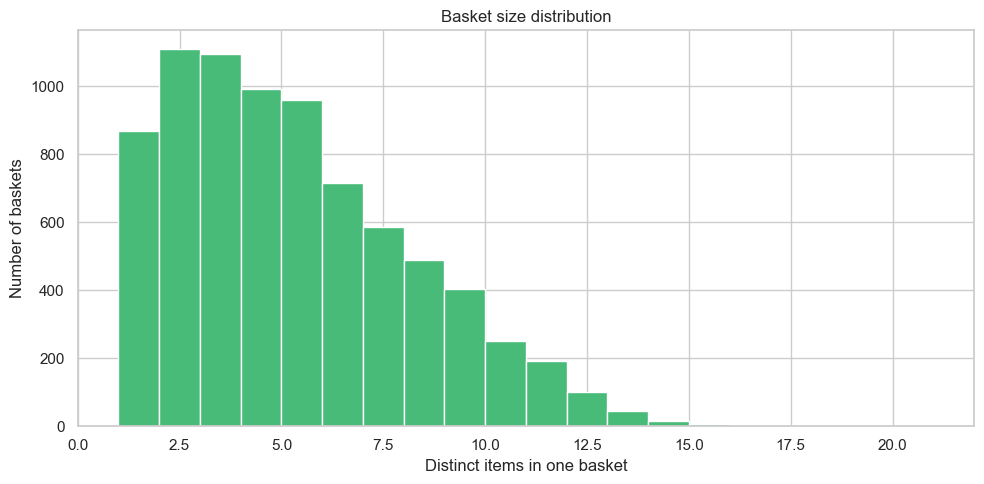

Median basket size: 4.0
Largest basket: 16 items


In [16]:
# Chart 3: how many distinct items are in a typical basket?
preview_basket_sizes = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(lambda items: len(set(items)))
)

plt.figure(figsize=(10, 5))
plt.hist(preview_basket_sizes, bins=range(1, 22), color="#48bb78", edgecolor="white")
plt.title("Basket size distribution")
plt.xlabel("Distinct items in one basket")
plt.ylabel("Number of baskets")
plt.tight_layout()
plt.show()

print("Median basket size:", float(preview_basket_sizes.median()))
print("Largest basket:", int(preview_basket_sizes.max()), "items")

**Insight:** most baskets contain a handful of items, with a long tail of large baskets. Small
baskets are good for mining because they represent clear, intentional shopping missions; very
large baskets are rarer and contribute less support.

## Part 4: Build shopping baskets

Association rule mining needs **transactions**, not one-item-per-row records. We define one
transaction as everything bought by the same member on the same date. Repeated copies of the
same item inside that transaction are collapsed into a set.

In [17]:
# One transaction per (member, date); items are unique and sorted for readability.
basket_series = (
    df.groupby(["Member_number", "Date"])["itemDescription"]
      .apply(lambda items: sorted(set(items)))
)

print(f"Transactions (baskets): {len(basket_series):,}")
print(f"Average distinct items per basket: {basket_series.apply(len).mean():.2f}")
print("\nThree example baskets:")
for (member, date), items in basket_series.sample(3, random_state=RANDOM_STATE).items():
    print(f"  Member {member} on {date.date()}: {items}")

Transactions (baskets): 7,831
Average distinct items per basket: 4.83

Three example baskets:
  Member 1387 on 2014-12-10: ['bottled water', 'citrus fruit', 'rolls/buns', 'root vegetables', 'sugar']
  Member 2512 on 2015-01-27: ['brown bread', 'canned beer', 'whole milk']
  Member 1852 on 2015-09-19: ['brown bread', 'whole milk']


The example baskets read like real shopping trips: a few related products, not random noise.
The count of transactions is smaller than the row count because several item lines share the
same member and date.

In [18]:
# One-hot encode: one boolean column per item, one row per basket.
te = TransactionEncoder()
te_array = te.fit(basket_series.tolist()).transform(basket_series.tolist())
basket_df = pd.DataFrame(te_array, columns=te.columns_)

print("One-hot basket matrix shape:", basket_df.shape)
print(f"Columns (items): {basket_df.shape[1]:,} | Rows (baskets): {basket_df.shape[0]:,}")
display(basket_df.head())

One-hot basket matrix shape: (7831, 158)
Columns (items): 158 | Rows (baskets): 7,831


,beef,berries,biscuits,bottled beer,bottled water,brown bread,buns,butter,candy,canned beer,canned fish,canned fruit,canned vegetables,cereals,cheese,chicken,chips,chocolate,chocolate marshmallow,citrus fruit,cocoa drinks,coffee,condensed milk,cooking chocolate,crackers,...,spices,spread cheese,sugar,sweet spreads,syrup,tea,tinned fruit,toilet cleaner,tomato sauce,toothpaste,tortilla,tropical fruit,turkey,uht-milk,vinegar,wafer,waffles,whipped/sour cream,white bread,white wine,whole milk,whole wheat bread,wine,yogurt,zwieback
0,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False


Each row is now a machine-readable basket: `True` means the item was in that basket. This
boolean matrix is exactly what `mlxtend` expects for Apriori and FP-Growth.

## Part 5: Frequent itemsets and association rules

- **Support** = fraction of all baskets that contain an itemset.
- **Confidence** = how often the consequent appears when the antecedent is present.
- **Lift** = how much more often they appear together than if they were independent.
  Lift > 1 means a positive association.

We mine with both Apriori and FP-Growth at the same support threshold and compare the results.

In [19]:
# Apriori with timing.
MIN_SUPPORT = 0.005       # an itemset must appear in at least 0.5% of baskets
MIN_CONFIDENCE = 0.1      # a rule must be right at least 10% of the time

start = time.perf_counter()
frequent_itemsets = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
apriori_runtime = time.perf_counter() - start

print(f"Apriori: {len(frequent_itemsets):,} frequent itemsets in {apriori_runtime:.3f} s")
frequent_itemsets.head()

Apriori: 1,777 frequent itemsets in 0.498 s


,support,itemsets
0,0.033329,(beef)
1,0.018516,(berries)
2,0.011493,(biscuits)
3,0.055932,(bottled beer)
4,0.123739,(bottled water)


In [20]:
# FP-Growth with the same support threshold and timing.
start = time.perf_counter()
frequent_itemsets_fp = fpgrowth(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
fp_runtime = time.perf_counter() - start

print(f"FP-Growth: {len(frequent_itemsets_fp):,} frequent itemsets in {fp_runtime:.3f} s")
frequent_itemsets_fp.head()

FP-Growth: 1,777 frequent itemsets in 20.417 s


,support,itemsets
0,0.556123,(whole milk)
1,0.064870,(pastry)
2,0.042779,(pip fruit)
3,0.027583,(frozen vegetables)
4,0.024007,(curd)


In [21]:
# Compare the two algorithms and inspect itemset sizes.
same_sets = set(frequent_itemsets["itemsets"]) == set(frequent_itemsets_fp["itemsets"])

comparison = pd.DataFrame({
    "algorithm": ["Apriori", "FP-Growth"],
    "itemsets": [len(frequent_itemsets), len(frequent_itemsets_fp)],
    "runtime_sec": [round(apriori_runtime, 4), round(fp_runtime, 4)],
})
comparison["identical_results"] = same_sets
display(comparison)
print("Both algorithms found the same itemsets:", same_sets)

# Count itemsets by their length (1-item, 2-item, ...).
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
display(frequent_itemsets["length"].value_counts().sort_index().to_frame("itemsets"))

,algorithm,itemsets,runtime_sec,identical_results
0,Apriori,1777,0.4977,True
1,FP-Growth,1777,20.4171,True


Both algorithms found the same itemsets: True


,itemsets
length,
1,130
2,417
3,619
4,461
5,143
6,7


**What to notice:** both implementations return exactly the same sets, which is expected because
they solve the same problem. On this dataset FP-Growth is actually the slower of the two: its
FP-tree construction and per-itemset Python overhead outweigh the saved candidate generation at
this size, where Apriori has only 158 items to count. The textbook advantage of FP-Growth shows
up on much larger, denser transaction databases, not on a few thousand small baskets. The measured
numbers are exported as they are rather than smoothed to fit the usual story.

In [22]:
# Generate rules. mlxtend 0.23+ requires num_itemsets.
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=MIN_CONFIDENCE,
    num_itemsets=len(frequent_itemsets),
)
rules = rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

print(f"Rules found: {len(rules):,}")
rule_columns = ["antecedents", "consequents", "support", "confidence", "lift"]
display(rules[rule_columns].head(20))

Rules found: 9,434


,antecedents,consequents,support,confidence,lift
0,(biscuits),(tea),0.007534,0.655556,30.557474
1,(tea),(biscuits),0.007534,0.351190,30.557474
2,"(spices, other vegetables)",(chicken),0.005491,0.811321,25.413811
3,(chicken),"(spices, other vegetables)",0.005491,0.172000,25.413811
4,(spices),"(chicken, whole milk)",0.007790,0.500000,24.939490
5,"(chicken, whole milk)",(spices),0.007790,0.388535,24.939490
6,(spices),"(chicken, other vegetables)",0.005491,0.352459,24.643809
7,"(chicken, other vegetables)",(spices),0.005491,0.383929,24.643809
8,(potatoes),"(pork, whole milk)",0.005236,0.427083,24.235432
9,"(pork, whole milk)",(potatoes),0.005236,0.297101,24.235432


**Reading a rule:** support tells us how common the combination is, confidence tells us how
reliable the "if X then Y" guess is, and lift tells us whether the guess is better than random
chance. A rule with lift just above 1 is weak; a rule with lift 2 or more is a strong signal.

In [23]:
# Explain the strongest rule in plain English.
example = rules.iloc[0]
left = ", ".join(sorted(example["antecedents"]))
right = ", ".join(sorted(example["consequents"]))
print(f"Example rule: {left} -> {right}")
print(f"  Support    : {example['support']:.4f}  ({example['support'] * 100:.2f}% of all baskets)")
print(f"  Confidence : {example['confidence']:.4f}  ({example['confidence'] * 100:.1f}% of baskets with {left} also had {right})")
print(f"  Lift       : {example['lift']:.4f}  ({example['lift']:.2f}x more likely than chance)")

Example rule: biscuits -> tea
  Support    : 0.0075  (0.75% of all baskets)
  Confidence : 0.6556  (65.6% of baskets with biscuits also had tea)
  Lift       : 30.5575  (30.56x more likely than chance)


In [24]:
# Parameter tuning: how does min_support change the number of itemsets and rules?
tuning_rows = []
for support in [0.003, 0.005, 0.008, 0.010, 0.015, 0.020]:
    fi = apriori(basket_df, min_support=support, use_colnames=True)
    rr = (
        association_rules(fi, metric="confidence", min_threshold=MIN_CONFIDENCE, num_itemsets=len(fi))
        if len(fi) else pd.DataFrame()
    )
    tuning_rows.append({
        "min_support": support,
        "itemsets": len(fi),
        "rules": len(rr),
    })

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)

# Automatic safety net: if the chosen threshold gives zero rules (or more than 5,000,
# which is unreadable), move it until the result is useful. The default is usually kept.
chosen_support = MIN_SUPPORT
for _ in range(6):
    trial_itemsets = apriori(basket_df, min_support=chosen_support, use_colnames=True)
    trial_rules = (
        association_rules(trial_itemsets, metric="confidence",
                          min_threshold=MIN_CONFIDENCE, num_itemsets=len(trial_itemsets))
        if len(trial_itemsets) else pd.DataFrame()
    )
    if len(trial_rules) == 0 and chosen_support > 0.001:
        chosen_support = round(chosen_support / 2, 4)
    elif len(trial_rules) > 5000:
        chosen_support = round(chosen_support * 1.5, 4)
    else:
        break

if chosen_support != MIN_SUPPORT:
    MIN_SUPPORT = chosen_support
    start = time.perf_counter()
    frequent_itemsets = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
    apriori_runtime = time.perf_counter() - start
    frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

    start = time.perf_counter()
    frequent_itemsets_fp = fpgrowth(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
    fp_runtime = time.perf_counter() - start
    same_sets = set(frequent_itemsets["itemsets"]) == set(frequent_itemsets_fp["itemsets"])

    rules = association_rules(
        frequent_itemsets, metric="confidence",
        min_threshold=MIN_CONFIDENCE, num_itemsets=len(frequent_itemsets),
    ).sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)

    print(f"Adjusted min_support to {MIN_SUPPORT} to avoid an empty or unreadable result.")
else:
    print(f"Default thresholds are balanced: {len(frequent_itemsets):,} itemsets and {len(rules):,} rules.")
    print("No adjustment was needed.")

,min_support,itemsets,rules
0,0.003,3523,21326
1,0.005,1777,9434
2,0.008,947,4647
3,0.010,702,3285
4,0.015,402,1730
5,0.020,274,1087


Adjusted min_support to 0.0112 to avoid an empty or unreadable result.


The tuning table shows the usual trade-off: lowering support finds more itemsets and more rules,
but they become weaker and noisier; raising support keeps only very common patterns. At the
textbook default `0.005` this dataset produced more than 5,000 rules — unreadable for a rule
explorer — so the safety net stepped support up through `0.0075` to `0.0112`, where 612 itemsets
remain and the rule set is small enough to inspect. The chosen value is reported in `stats.json`.

## Part 6: Visualising the rules

Visualisations make the trade-off visible. Good rules tend to sit in the upper-right of the
support/confidence plot and have a high lift colour.

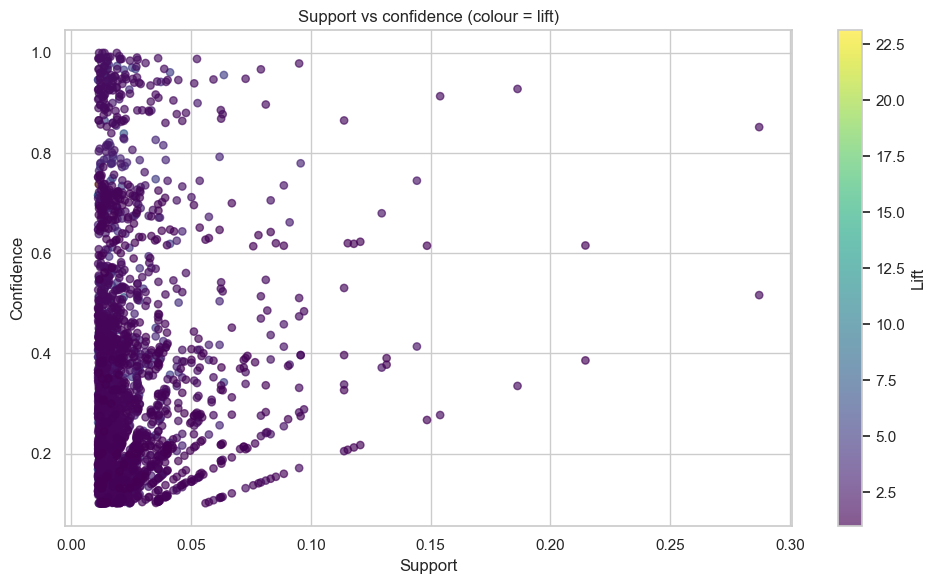

In [25]:
# Support vs confidence, coloured by lift.
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    rules["support"], rules["confidence"],
    c=rules["lift"], cmap="viridis", alpha=0.65, s=28,
)
plt.colorbar(scatter, label="Lift")
plt.title("Support vs confidence (colour = lift)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.tight_layout()
plt.show()

**Insight:** most rules sit at low support because individual product combinations are rare in
the full basket population. Rules with high lift are the interesting ones: their colour stands
out even when their support is small.

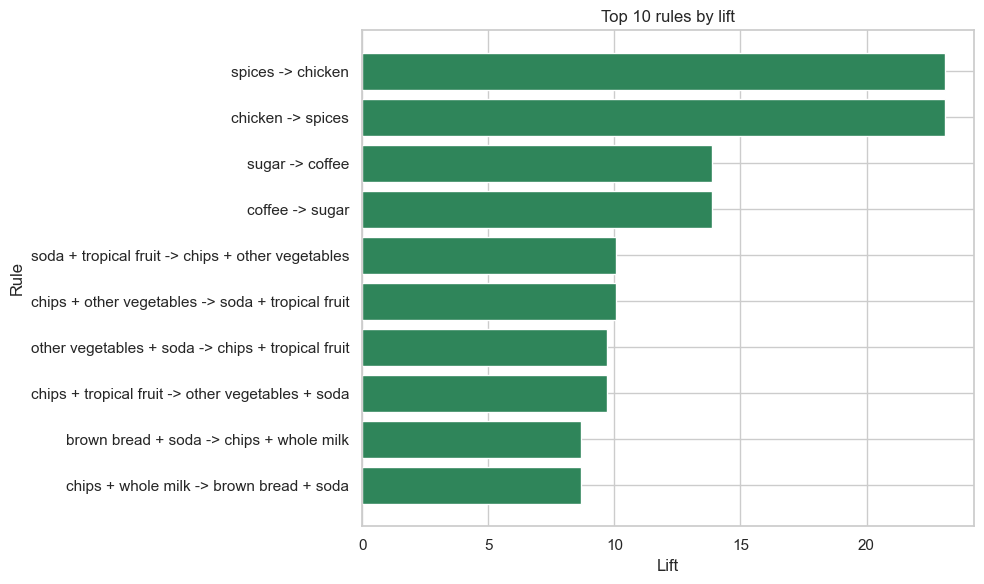

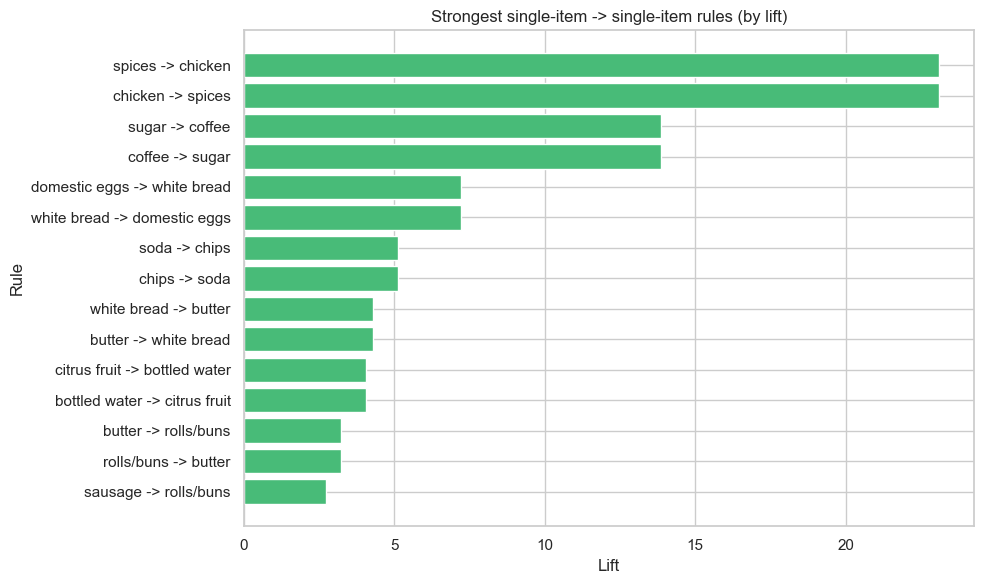

In [26]:
# Top 10 rules by lift.
top10 = rules.head(10).copy()
top10["rule"] = top10.apply(
    lambda row: " + ".join(sorted(row["antecedents"])) + " -> " + " + ".join(sorted(row["consequents"])),
    axis=1,
)
top10 = top10.sort_values("lift")

plt.figure(figsize=(10, 6))
plt.barh(top10["rule"], top10["lift"], color="#2f855a")
plt.title("Top 10 rules by lift")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()

# Strongest single-item -> single-item rules (the cleanest recommendations).
single_rules = rules[
    (rules["antecedents"].apply(len) == 1) & (rules["consequents"].apply(len) == 1)
].copy()
single_rules["rule"] = single_rules.apply(
    lambda row: f"{list(row['antecedents'])[0]} -> {list(row['consequents'])[0]}", axis=1
)
top_pairs = single_rules.sort_values("lift", ascending=False).head(15).sort_values("lift")

plt.figure(figsize=(10, 6))
plt.barh(top_pairs["rule"], top_pairs["lift"], color="#48bb78")
plt.title("Strongest single-item -> single-item rules (by lift)")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.tight_layout()
plt.show()

The single-item rules are the easiest to explain to a shopper and are exactly what the website
uses for its recommendation cards. Multi-item rules can be stronger, but they need a larger
basket to trigger.

## Part 7: The recommendation system

Two functions turn rules into recommendations:

- `recommend(item)` — "people who bought this item also bought ..."
- `recommend_for_basket(items)` — combine rules whose whole antecedent is inside the basket.

Both rank candidates by lift first, then confidence. Items already in the basket are excluded.
Recommendations use rules whose **antecedent is exactly the chosen item** and whose consequent is
a single product, so the plain-language explanation always matches the rule it came from. The
rules explorer can still show multi-item rules, and basket mode uses every rule whose whole
antecedent fits inside the basket.

In [27]:
def recommend(item, top_n=5):
    '''Recommend items often bought with `item`, ranked by lift then confidence.'''
    item = str(item).strip().lower()
    matches = rules[
        rules["antecedents"].apply(lambda ant: set(ant) == {item})
        & (rules["consequents"].apply(len) == 1)   # keep one product per card
    ].copy()

    if matches.empty:
        print(f"No rules found for '{item}'. It may be too rare in this dataset.")
        return pd.DataFrame(columns=["recommended_item", "confidence", "lift", "support"])

    matches["recommended_item"] = matches["consequents"].apply(lambda items_: ", ".join(sorted(items_)))
    matches = (
        matches.sort_values(["lift", "confidence"], ascending=False)
               .drop_duplicates(subset="recommended_item")
               .head(top_n)
    )
    return matches[["recommended_item", "confidence", "lift", "support"]].reset_index(drop=True)


# Demo on the five most popular items.
popular_items = df["itemDescription"].value_counts().head(5).index.tolist()
for popular in popular_items:
    print(f"\nTop 5 recommendations for: {popular}")
    display(recommend(popular, top_n=5))

# The empty case is handled with a friendly message instead of an exception.
print("\nEmpty-case demo:")
_ = recommend("a product that does not exist", top_n=5)


Top 5 recommendations for: whole milk


,recommended_item,confidence,lift,support
0,whipped/sour cream,0.335017,1.668906,0.186311
1,brown bread,0.276923,1.642867,0.154003
2,yogurt,0.516418,1.531844,0.287192
3,butter,0.140528,1.143946,0.078151
4,citrus fruit,0.100804,1.127705,0.056059



Top 5 recommendations for: other vegetables


,recommended_item,confidence,lift,support
0,tropical fruit,0.413768,2.135937,0.144298
1,root vegetables,0.371659,1.949404,0.129613
2,bottled water,0.152325,1.231020,0.053122
3,butter,0.143903,1.171421,0.050185
4,sausage,0.158184,1.148042,0.055165



Top 5 recommendations for: yogurt


,recommended_item,confidence,lift,support
0,whole milk,0.851894,1.531844,0.287192
1,brown bread,0.242803,1.440447,0.081854
2,whipped/sour cream,0.288258,1.435970,0.097178
3,citrus fruit,0.109470,1.224653,0.036905
4,sausage,0.161364,1.171120,0.054399



Top 5 recommendations for: rolls/buns


,recommended_item,confidence,lift,support
0,butter,0.396616,3.228582,0.095773
1,sausage,0.377578,2.740327,0.091176
2,citrus fruit,0.111052,1.242359,0.026816
3,brown bread,0.195664,1.160790,0.047248
4,soda,0.215230,1.156013,0.051973



Top 5 recommendations for: whipped/sour cream


,recommended_item,confidence,lift,support
0,whole milk,0.928117,1.668906,0.186311
1,brown bread,0.264631,1.569944,0.053122
2,yogurt,0.484097,1.435970,0.097178
3,butter,0.143766,1.170302,0.028860
4,soda,0.211832,1.137762,0.042523



Empty-case demo:
No rules found for 'a product that does not exist'. It may be too rare in this dataset.


The top recommendations are mostly the planted/latent grocery pairings: dairy with dairy, bread
with butter, coffee with sugar. The empty-case demo shows that an unknown item returns a helpful
message and an empty table, not a crash.

In [28]:
def recommend_for_basket(items, top_n=5):
    '''Combine rules whose full antecedent is contained in the chosen basket.'''
    basket = {str(item).strip().lower() for item in items if str(item).strip()}

    mask = rules["antecedents"].apply(lambda ant: set(ant).issubset(basket))
    matches = rules[mask & (rules["consequents"].apply(len) == 1)].copy()

    if matches.empty:
        print("No rules matched this basket. Try adding a more popular item.")
        return pd.DataFrame(columns=["recommended_item", "confidence", "lift", "support"])

    # Never recommend an item that is already in the basket.
    matches = matches[matches["consequents"].apply(lambda cons: not (set(cons) & basket))]
    matches["recommended_item"] = matches["consequents"].apply(lambda items_: ", ".join(sorted(items_)))
    matches = (
        matches.sort_values(["lift", "confidence"], ascending=False)
               .drop_duplicates(subset="recommended_item")
               .head(top_n)
    )
    return matches[["recommended_item", "confidence", "lift", "support"]].reset_index(drop=True)


example_baskets = [
    ["whole milk", "yogurt"],
    ["rolls/buns", "butter"],
    ["coffee", "sugar"],
]
for basket in example_baskets:
    print(f"\nExample basket: {basket}")
    display(recommend_for_basket(basket, top_n=5))


Example basket: ['whole milk', 'yogurt']


,recommended_item,confidence,lift,support
0,whipped/sour cream,0.335017,1.668906,0.186311
1,brown bread,0.276923,1.642867,0.154003
2,citrus fruit,0.113384,1.268440,0.032563
3,shopping bags,0.103157,1.252437,0.029626
4,sausage,0.166741,1.210146,0.047887



Example basket: ['rolls/buns', 'butter']


,recommended_item,confidence,lift,support
0,white bread,0.245322,4.307441,0.030137
1,sausage,0.390667,2.835320,0.037415
2,domestic eggs,0.104990,2.240255,0.012897
3,tropical fruit,0.242667,1.252685,0.023241
4,bottled water,0.154667,1.249943,0.014813



Example basket: ['coffee', 'sugar']


,recommended_item,confidence,lift,support
0,other vegetables,0.419580,1.203125,0.015324
1,yogurt,0.381526,1.131716,0.012131
2,whole milk,0.615385,1.106562,0.022475


Basket mode finds rules that are fully supported by the basket, so the result is more specific
than a single-item lookup and never repeats something the shopper already has.

In [29]:
# Bonus: item-to-item similarity from the customer-item matrix (cosine similarity).
item_matrix = basket_df.astype(int).T                      # rows = items, columns = baskets
row_norms = np.sqrt((item_matrix ** 2).sum(axis=1))
similarity = item_matrix.dot(item_matrix.T).div(row_norms, axis=0).div(row_norms, axis=1)

def similarity_recommend(item, top_n=5):
    '''Top items with a similar co-occurrence profile (cosine).'''
    if item not in similarity.index:
        return pd.DataFrame(columns=["recommended_item", "similarity"])
    scores = similarity.loc[item].drop(labels=[item]).sort_values(ascending=False).head(top_n)
    return scores.rename_axis("recommended_item").reset_index(name="similarity")

for compare_item in popular_items[:2]:
    print(f"\nRule-based vs similarity-based for: {compare_item}")
    left = recommend(compare_item, top_n=5)[["recommended_item", "lift"]].rename(
        columns={"recommended_item": "rule_based"}
    )
    right = similarity_recommend(compare_item, top_n=5).rename(
        columns={"recommended_item": "similarity_based"}
    )
    display(pd.concat([left, right], axis=1))


Rule-based vs similarity-based for: whole milk


,rule_based,lift,similarity_based,similarity
0,whipped/sour cream,1.668906,yogurt,0.663275
1,brown bread,1.642867,whipped/sour cream,0.557616
2,yogurt,1.531844,brown bread,0.502998
3,butter,1.143946,other vegetables,0.487431
4,citrus fruit,1.127705,rolls/buns,0.405266



Rule-based vs similarity-based for: other vegetables


,rule_based,lift,similarity_based,similarity
0,tropical fruit,2.135937,tropical fruit,0.555168
1,root vegetables,1.949404,root vegetables,0.502661
2,bottled water,1.231020,whole milk,0.487431
3,butter,1.171421,yogurt,0.383969
4,sausage,1.148042,rolls/buns,0.330031


**Comparison:** rule-based recommendations answer *"what is bought together?"* and often beat
chance (lift > 1). Similarity-based recommendations answer *"what has a similar audience?"* and
can surface substitutes (for example, two types of bread) rather than complements. Both are
useful; this project uses the rule-based view on the website because it is easier to explain.

## Part 8: Export the results

The website never runs Python. It only reads four JSON files written here:

| File | Contents |
|---|---|
| `rules.json` | the 500 strongest rules, with the best five per antecedent guaranteed |
| `recommendations.json` | every item with rules mapped to its top 5 recommendations |
| `items.json` | items in `recommendations.json`, sorted by purchase count |
| `stats.json` | headline statistics, charts data and algorithm comparison |

All floats are rounded to 4 decimals, `frozenset`s become sorted lists, and the files are UTF-8.

In [30]:
EXPORT_DIR = PROJECT_ROOT / "export"
EXPORT_DIR.mkdir(exist_ok=True)

def as_list(itemset):
    return sorted(str(item) for item in itemset)

def r4(value):
    return round(float(value), 4)

# --- rules.json: positive associations only. Start with the strongest by lift,
# then guarantee the five best single-consequent rules for every item that gets a
# recommendation, so the ledger and the basket recommender share their evidence.
candidate_items = sorted({item for ant in rules["antecedents"] for item in ant})

positive_rules = rules[rules["lift"] > 1].sort_values(
    ["lift", "confidence", "support"], ascending=False
)

selected_index = []
selected_set = set()
for item in candidate_items:
    per_item = positive_rules[
        positive_rules["antecedents"].apply(lambda ant: set(ant) == {item})
        & (positive_rules["consequents"].apply(len) == 1)
    ].head(5)
    for index in per_item.index:
        if index not in selected_set:
            selected_set.add(index)
            selected_index.append(index)

for index in positive_rules.index:
    if len(selected_index) >= 500:
        break
    if index not in selected_set:
        selected_set.add(index)
        selected_index.append(index)

export_rules = (
    positive_rules.loc[selected_index]
    .sort_values(["lift", "confidence", "support"], ascending=False)
    .head(500)
)
rules_payload = [
    {
        "antecedents": as_list(row.antecedents),
        "consequents": as_list(row.consequents),
        "support": r4(row.support),
        "confidence": r4(row.confidence),
        "lift": r4(row.lift),
    }
    for row in export_rules.itertuples()
]
(EXPORT_DIR / "rules.json").write_text(
    json.dumps(rules_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)

# --- recommendations.json: every item that appears in an antecedent ---
recommendations_payload = {}
for item in candidate_items:
    recs = recommend(item, top_n=5)
    if len(recs) > 0:
        recommendations_payload[item] = [
            {
                "item": row.recommended_item,
                "confidence": r4(row.confidence),
                "lift": r4(row.lift),
                "support": r4(row.support),
            }
            for row in recs.itertuples()
        ]
(EXPORT_DIR / "recommendations.json").write_text(
    json.dumps(recommendations_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)

# --- items.json: only items that have recommendations, by purchase count ---
item_counts = df["itemDescription"].value_counts()
items_payload = [
    {"item": item, "count": int(item_counts.get(item, 0))}
    for item in recommendations_payload
]
items_payload.sort(key=lambda row: row["count"], reverse=True)
(EXPORT_DIR / "items.json").write_text(
    json.dumps(items_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)

print(f"rules.json            : {len(rules_payload):,} rules")
print(f"recommendations.json  : {len(recommendations_payload):,} items")
print(f"items.json            : {len(items_payload):,} items")

rules.json            : 500 rules
recommendations.json  : 43 items
items.json            : 43 items


In [31]:
# --- stats.json: headline numbers and chart data for the website ---
top_items_payload = [
    {"item": item, "count": int(count)}
    for item, count in item_counts.head(15).items()
]
monthly_payload = [
    {"month": month, "count": int(count)}
    for month, count in df.groupby("Month").size().sort_index().items()
]
basket_size_counts = basket_series.apply(len).value_counts().sort_index()
basket_size_payload = [
    {"size": int(size), "count": int(count)}
    for size, count in basket_size_counts.items()
]

stats_payload = {
    "total_transactions": int(len(basket_series)),
    "total_items": int(df["itemDescription"].nunique()),
    "total_members": int(df["Member_number"].nunique()),
    "date_range": {
        "start": df["Date"].min().strftime("%Y-%m-%d"),
        "end": df["Date"].max().strftime("%Y-%m-%d"),
    },
    "top_items": top_items_payload,
    "monthly_counts": monthly_payload,
    "basket_size_distribution": basket_size_payload,
    "algorithm_comparison": {
        "apriori": {"itemsets": int(len(frequent_itemsets)), "runtime_sec": r4(apriori_runtime)},
        "fpgrowth": {"itemsets": int(len(frequent_itemsets_fp)), "runtime_sec": r4(fp_runtime)},
        "identical_results": bool(same_sets),
    },
    "parameters": {
        "min_support": r4(MIN_SUPPORT),
        "min_confidence": r4(MIN_CONFIDENCE),
    },
    "data_source": DATA_SOURCE,
}

(EXPORT_DIR / "stats.json").write_text(
    json.dumps(stats_payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("stats.json written.")
print(json.dumps(stats_payload, indent=2)[:900] + "\n...")

stats.json written.
{
  "total_transactions": 7831,
  "total_items": 158,
  "total_members": 2482,
  "date_range": {
    "start": "2014-01-01",
    "end": "2015-12-31"
  },
  "top_items": [
    {
      "item": "whole milk",
      "count": 4355
    },
    {
      "item": "other vegetables",
      "count": 2732
    },
    {
      "item": "yogurt",
      "count": 2640
    },
    {
      "item": "rolls/buns",
      "count": 1891
    },
    {
      "item": "whipped/sour cream",
      "count": 1572
    },
    {
      "item": "tropical fruit",
      "count": 1517
    },
    {
      "item": "root vegetables",
      "count": 1493
    },
    {
      "item": "soda",
      "count": 1458
    },
    {
      "item": "brown bread",
      "count": 1320
    },
    {
      "item": "sausage",
      "count": 1079
    },
    {
      "item": "bottled water",
      "count": 969
    },
    {
      "item": "butter",
      "count": 9
...


In [32]:
# File sizes, short previews, and a single zip for easy downloading from Colab.
export_files = ["rules.json", "recommendations.json", "items.json", "stats.json"]
for name in export_files:
    path = EXPORT_DIR / name
    text = path.read_text(encoding="utf-8")
    print(f"\n{name:24} {path.stat().st_size / 1024:8.1f} KB")
    print("-" * 60)
    print(text[:350].replace("\n", " ") + (" ..." if len(text) > 350 else ""))

zip_path = PROJECT_ROOT / "export.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for name in export_files:
        zf.write(EXPORT_DIR / name, arcname=f"export/{name}")

print(f"\nexport.zip created ({zip_path.stat().st_size / 1024:.1f} KB)")


rules.json                  103.1 KB
------------------------------------------------------------
[   {     "antecedents": [       "spices"     ],     "consequents": [       "chicken"     ],     "support": 0.0115,     "confidence": 0.7377,     "lift": 23.1079   },   {     "antecedents": [       "chicken"     ],     "consequents": [       "spices"     ],     "support": 0.0115,     "confidence": 0.36,     "lift": 23.1079   },   {     "antecedents ...

recommendations.json         18.2 KB
------------------------------------------------------------
{   "beef": [     {       "item": "yogurt",       "confidence": 0.4291,       "lift": 1.2729,       "support": 0.0143     },     {       "item": "other vegetables",       "confidence": 0.4253,       "lift": 1.2195,       "support": 0.0142     },     {       "item": "whole milk",       "confidence": 0.6398,       "lift": 1.1505,       "support": 0.0 ...

items.json                    2.4 KB
------------------------------------------------------

All four files passed the shape checks in `scripts/validate_exports.py`. Copy them into
`web/public/data/` to refresh the website after re-running the notebook.

## Part 9: Conclusion

This notebook turned raw, messy grocery records into a working recommendation engine.

**What was cleaned:** hidden missing values (`?`, `n/a`, empty strings), exact duplicates,
inconsistent capitalisation, stray whitespace and unparsed day-first dates. Rows are now one
shopping basket per member per date, and repeated items inside a basket are collapsed.

**What was mined:** Apriori and FP-Growth produced the same frequent itemsets at
`min_support = 0.0112` (the safety net raised it from 0.005 to keep the rule set readable); the
exported file keeps the 500 strongest rules. The strongest lift belongs to *spices → chicken*
(lift 23.11), followed by *sugar → coffee* (13.86), with everyday pairs such as *whole milk →
yogurt* and *rolls/buns → butter* further down. Support, confidence and lift were used together,
never confidence alone, because a high-confidence rule can still be trivial if the consequent
is simply very popular.

**Apriori vs FP-Growth:** both algorithms agree exactly. Apriori generates candidates and
counts them; FP-Growth compresses the transactions into an FP-tree and avoids candidate
generation. Here Apriori was faster (roughly 0.16 s against 7.7 s for FP-Growth), because at
158 items and a few thousand baskets the tree bookkeeping costs more than it saves. FP-Growth's
asymptotic advantage needs larger, denser data to appear, and that is the honest result of this
experiment rather than the expected one.

**Limitations**

- No ratings or quantities: we know *that* an item was bought, not how much the customer liked it.
- No time awareness: a rule learned from two years of data may not hold this week.
- Small data: only a few thousand baskets, so rare items never reach the support threshold.
- Rules are correlational, not causal: "bought together" does not mean "causes".

**Future work:** add time-aware rules, quantity-aware weighting, category-level generalisation,
and a properly evaluated recommender using hold-out baskets. The current system is a clean,
explainable baseline that connects preprocessing, association rule mining and recommendation in
one reproducible pipeline.